In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

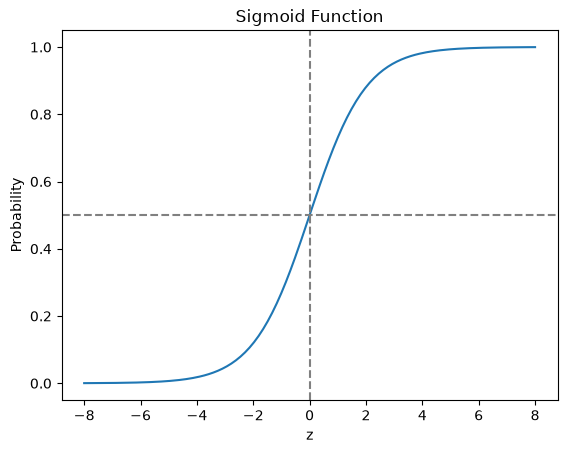

In [3]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.show()

In [4]:
hours = np.array([[1],[2],[3],[4],[5],[6],[7],[8],[9],[10]])
passed = np.array([0,0,0,0,0,1,1,1,1,1])

model = LogisticRegression()
model.fit(hours, passed)

print("Coefficient (b1):", model.coef_[0][0])
print("Intercept (b0)  :", model.intercept_[0])

Coefficient (b1): 1.1860640568835412
Intercept (b0)  : -6.523226379386811


In [5]:
b0 = model.intercept_[0]
b1 = model.coef_[0][0]

h = 5.5
z_val = b0 + b1 * h
manual_prob = 1 / (1 + np.exp(-z_val))

print("z =", z_val)
print("Manual probability :", manual_prob)
print("Model ki probability:", model.predict_proba([[h]])[0][1])

z = 0.00012593347266598443
Manual probability : 0.5000314833681249
Model ki probability: 0.5000314833681249


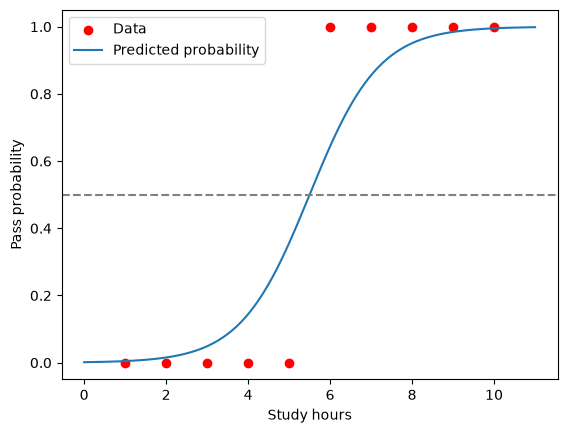

In [6]:
x_range = np.linspace(0, 11, 200).reshape(-1, 1)
probs = model.predict_proba(x_range)[:, 1]

plt.scatter(hours, passed, color="red", label="Data")
plt.plot(x_range, probs, label="Predicted probability")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Study hours")
plt.ylabel("Pass probability")
plt.legend()
plt.show()

In [7]:
print("b0 =", b0)
print("b1 =", b1)
print("Decision boundary x =", -b0 / b1)

b0 = -6.523226379386811
b1 = 1.1860640568835412
Decision boundary x = 5.499893822368248


In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix

# 6 ghante study par pass ki probability
print(model.predict_proba([[6]]))   # [[P(fail), P(pass)]]

# Final class (0 = fail, 1 = pass)
print(model.predict([[4], [5], [6], [7]]))

# Poore data par accuracy aur confusion matrix
y = passed
y_pred = model.predict(hours)
print("Accuracy:", accuracy_score(y, y_pred))
print(confusion_matrix(y, y_pred))

[[0.3559106 0.6440894]]
[0 0 1 1]
Accuracy: 1.0
[[5 0]
 [0 5]]
